# Klasifikasi Jenis Beras (Rice Type Classification)

**Dataset:** `riceClassification.csv` (18.185 butir beras, 10 fitur geometri hasil pengolahan citra + kolom `Class`).

**Catatan penting:** kolom `Class` hanya bernilai **0 dan 1**, sehingga dataset ini sebenarnya **klasifikasi biner (2 jenis beras)**, bukan multikelas. Notebook ini tetap dikerjakan lengkap, dan perbedaannya dibahas di bagian kesimpulan.

**Pertanyaan yang ingin dijawab:**
1. Fitur bentuk apa yang paling membedakan kedua jenis beras?
2. Seberapa akurat model memprediksi jenis beras hanya dari ukuran dan bentuknya?

In [1]:
import glob, os
def cari(nama):
    # cari file di folder ini maupun subfolder
    h = glob.glob('**/'+nama, recursive=True)
    assert h, f"File {nama} tidak ditemukan di {os.getcwd()}"
    return h[0]
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
sns.set_theme(style='whitegrid')
df = pd.read_csv(cari('riceClassification.csv'))
df.head()

,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


## 1. Pemahaman Data

In [2]:
print(df.shape)
print('Missing value:', df.isna().sum().sum(), '| Duplikat:', df.duplicated().sum())
print('Jumlah kelas :', df['Class'].nunique(), '->', sorted(df['Class'].unique()))
print(df['Class'].value_counts(normalize=True).round(3))
df.describe().T

(18185, 12)
Missing value: 0 | Duplikat: 0
Jumlah kelas : 2 -> [np.int64(0), np.int64(1)]
Class
1    0.549
0    0.451
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
id,18185.0,9093.000000,5249.701658,1.000000,4547.000000,9093.000000,13639.000000,18185.000000
Area,18185.0,7036.492989,1467.197150,2522.000000,5962.000000,6660.000000,8423.000000,10210.000000
MajorAxisLength,18185.0,151.680754,12.376402,74.133114,145.675910,153.883750,160.056214,183.211434
MinorAxisLength,18185.0,59.807851,10.061653,34.409894,51.393151,55.724288,70.156593,82.550762
Eccentricity,18185.0,0.915406,0.030575,0.676647,0.891617,0.923259,0.941372,0.966774
ConvexArea,18185.0,7225.817872,1502.006571,2579.000000,6125.000000,6843.000000,8645.000000,11008.000000
EquivDiameter,18185.0,94.132952,9.906250,56.666658,87.126656,92.085696,103.559146,114.016559
Extent,18185.0,0.616653,0.104389,0.383239,0.538530,0.601194,0.695664,0.886573
Perimeter,18185.0,351.606949,29.500620,197.015000,333.990000,353.088000,373.003000,508.511000
Roundness,18185.0,0.707998,0.067310,0.174590,0.650962,0.701941,0.769280,0.904748


**Temuan:** tidak ada *missing value* maupun duplikat. Hanya ada **2 kelas** (± 55% kelas 1 dan 45% kelas 0), jadi cukup seimbang. Kolom `id` hanya nomor urut sehingga dibuang dari fitur.

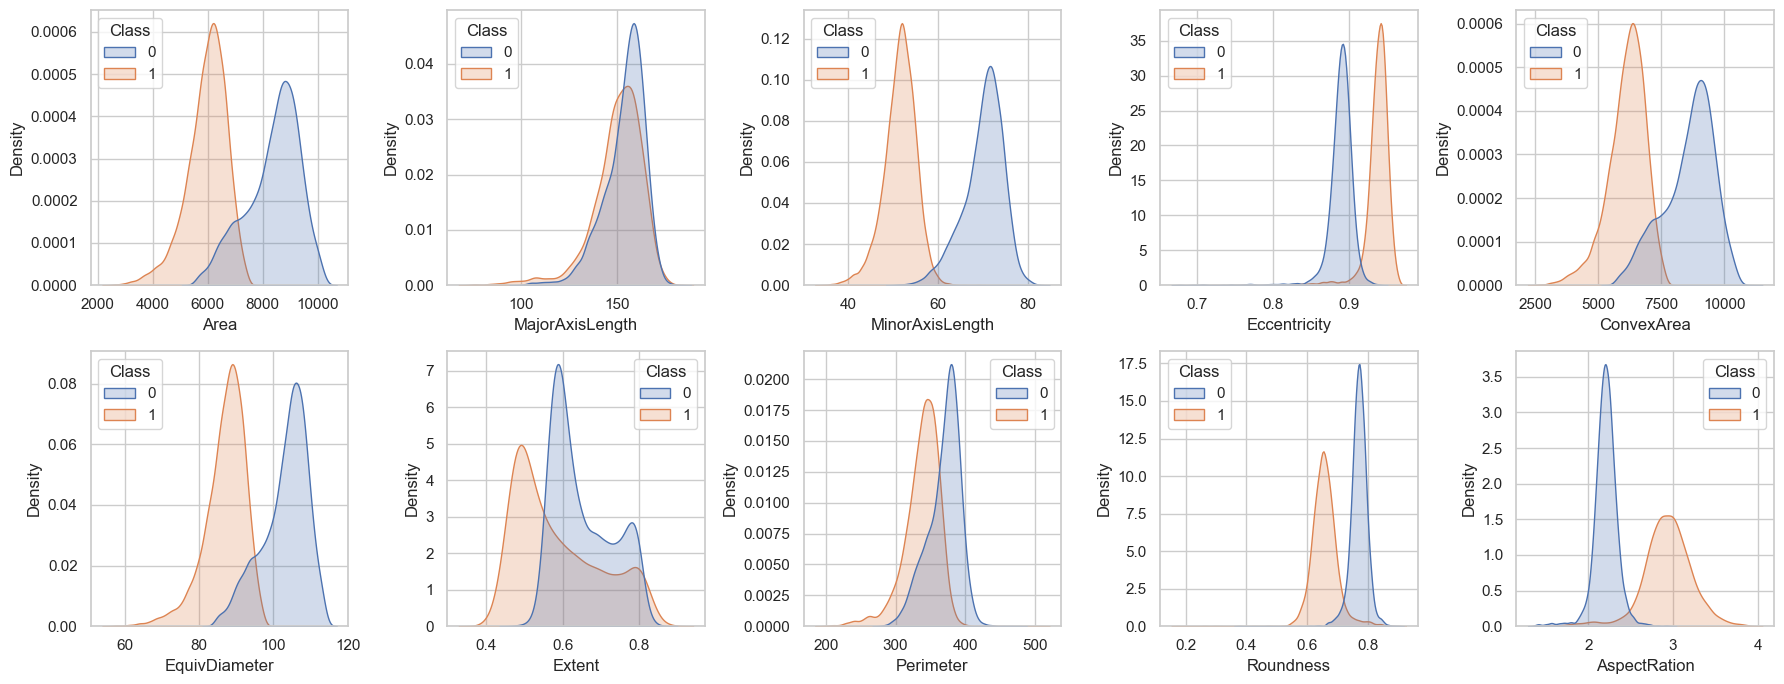

In [3]:
fitur = [c for c in df.columns if c not in ['id','Class']]
fig, axes = plt.subplots(2,5, figsize=(18,7))
for ax,c in zip(axes.ravel(), fitur):
    sns.kdeplot(data=df, x=c, hue='Class', fill=True, common_norm=False, ax=ax)
plt.tight_layout(); plt.show()

**Cara membaca:** kurva yang berjauhan antara kelas 0 dan 1 menandakan fitur pembeda yang kuat. Fitur yang kurvanya saling menumpuk kurang berguna untuk memisahkan kedua jenis.

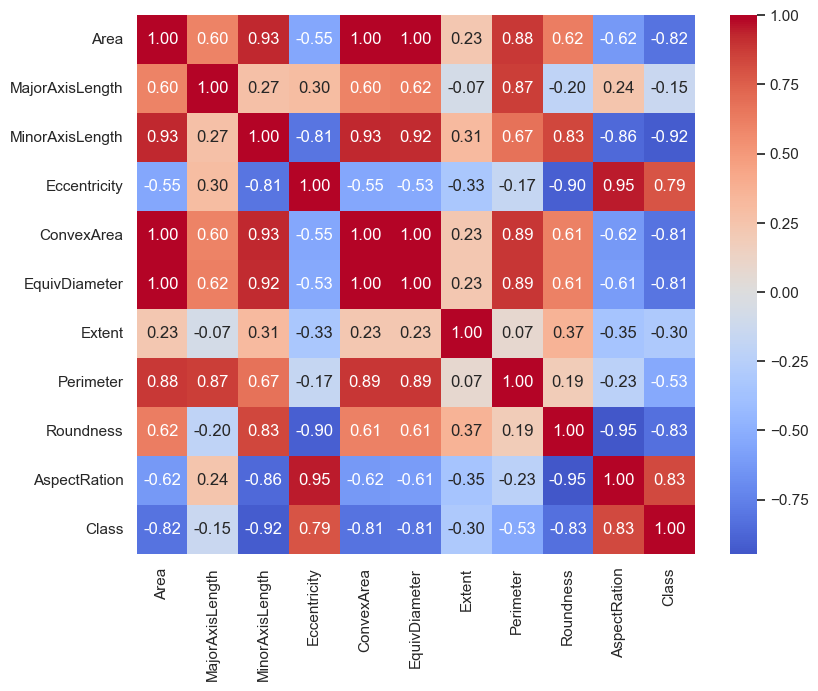

MinorAxisLength   -0.918
AspectRation       0.833
Roundness         -0.832
Area              -0.817
ConvexArea        -0.814
EquivDiameter     -0.809
Eccentricity       0.789
Perimeter         -0.533
Extent            -0.303
MajorAxisLength   -0.148
Name: Class, dtype: float64


In [4]:
plt.figure(figsize=(9,7))
sns.heatmap(df[fitur+['Class']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.show()
print(df[fitur+['Class']].corr()['Class'].drop('Class').sort_values(key=abs, ascending=False).round(3))

Banyak fitur saling berkorelasi sangat tinggi (misalnya `Area`, `ConvexArea`, `EquivDiameter`, `Perimeter`) karena semuanya mengukur ukuran butir. Ini tidak masalah bagi Random Forest, tetapi perlu diingat saat menafsirkan koefisien model linear.

## 2. Pemodelan

In [5]:
X, y = df[fitur], df['Class']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
models = {
 'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
 'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}
rows = {}
for n,m in models.items():
    cv = cross_val_score(m, Xtr, ytr, cv=5).mean()
    m.fit(Xtr, ytr); p = m.predict(Xte)
    rows[n] = dict(cv_acc=cv, test_acc=(p==yte).mean(), ROC_AUC=roc_auc_score(yte, m.predict_proba(Xte)[:,1]))
pd.DataFrame(rows).T.round(4)

,cv_acc,test_acc,ROC_AUC
Logistic Regression,0.9881,0.9920,0.9994
Random Forest,0.9885,0.9923,0.9989


              precision    recall  f1-score   support

           0     0.9939    0.9890    0.9914      1640
           1     0.9910    0.9950    0.9930      1997

    accuracy                         0.9923      3637
   macro avg     0.9924    0.9920    0.9922      3637
weighted avg     0.9923    0.9923    0.9923      3637



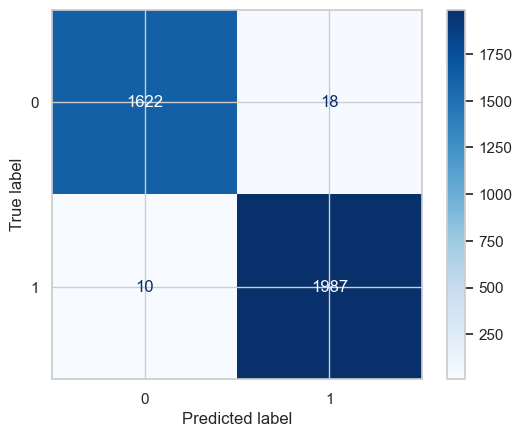

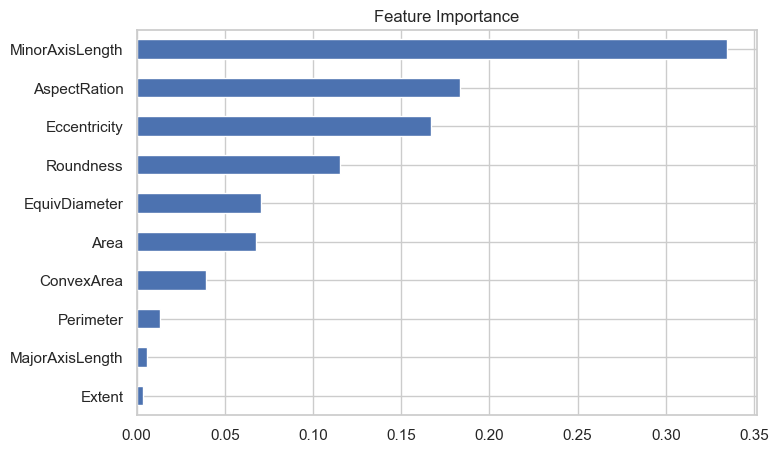

In [6]:
best = models['Random Forest']; p = best.predict(Xte)
print(classification_report(yte, p, digits=4))
ConfusionMatrixDisplay(confusion_matrix(yte,p)).plot(cmap='Blues'); plt.show()
pd.Series(best.feature_importances_, index=fitur).sort_values().plot.barh(figsize=(8,5), title='Feature Importance'); plt.show()

## 3. Kesimpulan
- Dataset ini **biner (2 kelas)**, bukan multikelas, sehingga lebih tepat ditempatkan di kelompok *Klasifikasi Biner*.
- Data bersih dan cukup seimbang, jadi akurasi dapat dipakai langsung sebagai metrik.
- Kedua model mencapai akurasi uji **± 99,2%** (ROC-AUC ± 0,999). Logistic Regression yang sederhana hampir sama bagusnya dengan Random Forest, artinya kedua jenis beras **hampir dapat dipisahkan secara linear** oleh fitur bentuk dan ukuran.
- Korelasi terkuat dengan kelas ada pada `MinorAxisLength` (± -0,92), `AspectRation` (± 0,83), dan `Roundness` (± -0,83).
- *Feature importance* menunjukkan fitur geometri mana yang paling menentukan; fitur ini yang paling layak dipertahankan bila ingin membuat model lebih sederhana.
- Akurasi setinggi ini pada data hasil ekstraksi citra yang bersih sebaiknya tidak langsung dianggap berlaku untuk foto beras di lapangan, karena kondisi pencahayaan dan posisi butir bisa berbeda.